# Bar Inventory Demand Forecast and Par-Level Planner

This notebook turns the supplied movement history into a first-pass forecast, a par-level target for each bar and brand, and a manager's replenishment watchlist. The code favors clear assumptions that can be changed by the hotel team.

The source is a set of dated records, not a complete daily sales ledger. A date without a row may mean no activity or an unrecorded movement. The first pass treats it as zero recorded consumption and displays record coverage beside each recommendation.


## 1. Setup

The path points to the supplied file. If you move the notebook, put the CSV beside it or change DATA_PATH. The lead time, review period, and service level are starter assumptions; confirm them with purchasing and bar managers.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
possible_paths = [
    Path(r"C:\Users\Anindya Pan\Downloads\Consumption Dataset - Dataset.csv"),
    Path("Consumption Dataset - Dataset.csv"),
    Path("data/Consumption Dataset - Dataset.csv"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), possible_paths[0])

LEAD_TIME_DAYS = 3
REVIEW_PERIOD_DAYS = 7
SERVICE_LEVEL = 0.95
FORECAST_WINDOW_WEEKS = 8
VALIDATION_WEEKS = 8
GROUP_COLS = ["Bar Name", "Alcohol Type", "Brand Name"]
TIME_COL = "Date Time Served"
DEMAND_COL = "Consumed (ml)"


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {DATA_PATH}. Update DATA_PATH or place the file beside this notebook.")

raw = pd.read_csv(DATA_PATH)
required = {TIME_COL, *GROUP_COLS, "Opening Balance (ml)", "Purchase (ml)",
            DEMAND_COL, "Closing Balance (ml)"}
missing = required.difference(raw.columns)
if missing:
    raise ValueError(f"Missing expected columns: {sorted(missing)}")

raw[TIME_COL] = pd.to_datetime(raw[TIME_COL], errors="coerce")
for column in ["Opening Balance (ml)", "Purchase (ml)", DEMAND_COL, "Closing Balance (ml)"]:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")
raw = raw.dropna(subset=[TIME_COL, *GROUP_COLS, DEMAND_COL]).copy()
raw["Date"] = raw[TIME_COL].dt.normalize()

print(f"Rows: {len(raw):,}")
print(f"Date range: {raw[TIME_COL].min():%Y-%m-%d} to {raw[TIME_COL].max():%Y-%m-%d}")
print(f"Bars: {raw['Bar Name'].nunique()} | Brands: {raw['Brand Name'].nunique()} | "
      f"Bar-brand combinations: {raw[GROUP_COLS].drop_duplicates().shape[0]}")
print("Missing fields after cleaning:", int(raw.isna().sum().sum()))


Rows: 6,575
Date range: 2023-01-01 to 2024-01-01
Bars: 6 | Brands: 16 | Bar-brand combinations: 96
Missing fields after cleaning: 0


## 2. Understand the recorded movement

The plots summarize recorded consumption; they are not adjusted for different logging frequencies.


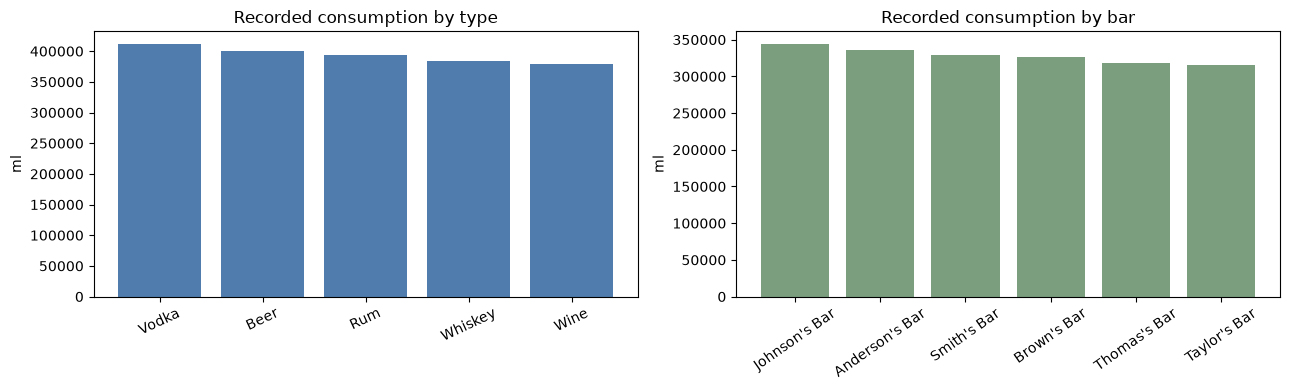

Average rows per bar-brand combination: 68.5


,Alcohol Type,Consumed (ml)
2,Vodka,411759.71
0,Beer,399498.39
1,Rum,393266.84
3,Whiskey,384754.46
4,Wine,379402.26


In [3]:
by_type = (raw.groupby("Alcohol Type", as_index=False)[DEMAND_COL]
           .sum().sort_values(DEMAND_COL, ascending=False))
by_bar = (raw.groupby("Bar Name", as_index=False)[DEMAND_COL]
          .sum().sort_values(DEMAND_COL, ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(by_type["Alcohol Type"], by_type[DEMAND_COL], color="#4f7cac")
axes[0].set(title="Recorded consumption by type", ylabel="ml")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(by_bar["Bar Name"], by_bar[DEMAND_COL], color="#7a9e7e")
axes[1].set(title="Recorded consumption by bar", ylabel="ml")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

print("Average rows per bar-brand combination:",
      round(len(raw) / raw[GROUP_COLS].drop_duplicates().shape[0], 1))
display(by_type)


## 3. Make daily series and check logging coverage

Rows for the same bar, brand, and calendar date are summed. We complete the calendar for each observed combination and fill dates without a row with zero recorded demand. The observed-day percentage remains visible because this assumption can understate real demand when logging is incomplete.


In [4]:
observed = (raw.groupby([*GROUP_COLS, "Date"], as_index=False)[DEMAND_COL]
            .sum().rename(columns={DEMAND_COL: "demand_ml"}))
dates = pd.date_range(raw["Date"].min(), raw["Date"].max(), freq="D")
items = raw[GROUP_COLS].drop_duplicates()
grid = items.merge(pd.DataFrame({"Date": dates}), how="cross")
daily = grid.merge(observed, on=[*GROUP_COLS, "Date"], how="left")
daily["observed_record"] = daily["demand_ml"].notna()
daily["demand_ml"] = daily["demand_ml"].fillna(0).clip(lower=0)

coverage = (daily.groupby(GROUP_COLS, as_index=False)
            .agg(recorded_days=("observed_record", "sum"),
                 calendar_days=("Date", "count")))
coverage["coverage_pct"] = 100 * coverage["recorded_days"] / coverage["calendar_days"]
display(coverage.sort_values("coverage_pct").head(10))


,Bar Name,Alcohol Type,Brand Name,recorded_days,calendar_days,coverage_pct
66,Taylor's Bar,Beer,Heineken,40,366,10.928962
17,Brown's Bar,Beer,Coors,46,366,12.568306
48,Smith's Bar,Beer,Budweiser,46,366,12.568306
49,Smith's Bar,Beer,Coors,47,366,12.841530
82,Thomas's Bar,Beer,Heineken,47,366,12.841530
80,Thomas's Bar,Beer,Budweiser,48,366,13.114754
0,Anderson's Bar,Beer,Budweiser,48,366,13.114754
16,Brown's Bar,Beer,Budweiser,49,366,13.387978
50,Smith's Bar,Beer,Heineken,50,366,13.661202
32,Johnson's Bar,Beer,Budweiser,52,366,14.207650


## 4. Compare a simple forecast with a baseline

For each combination, the candidate is the mean weekly demand from the previous eight weeks. We evaluate it on the final eight weeks with rolling, time-ordered predictions. The baseline uses the previous week's demand. WAPE is weighted absolute percentage error; lower is better. Since no-row dates are zero-filled, these scores share that limitation.


In [5]:
end_date = daily["Date"].max()
last_complete_week_end = end_date - pd.Timedelta(days=(end_date.weekday() + 1) % 7)
checks = []

for key, item_days in daily.groupby(GROUP_COLS, sort=False):
    weekly = item_days.set_index("Date")["demand_ml"].resample("W-SUN").sum().sort_index()
    weekly = weekly.loc[weekly.index <= last_complete_week_end]
    for week_end in weekly.index[-VALIDATION_WEEKS:]:
        history = weekly.loc[weekly.index < week_end]
        if len(history) < FORECAST_WINDOW_WEEKS:
            continue
        checks.append({
            **dict(zip(GROUP_COLS, key)),
            "actual": float(weekly.loc[week_end]),
            "moving_average": float(history.tail(FORECAST_WINDOW_WEEKS).mean()),
            "last_week": float(history.iloc[-1]),
        })

validation = pd.DataFrame(checks)
if validation.empty:
    raise ValueError("Not enough weekly history for validation.")

def metrics(actual, predicted):
    errors = np.abs(actual - predicted)
    total = np.abs(actual).sum()
    return {
        "MAE (ml/item-week)": errors.mean(),
        "WAPE (%)": 100 * errors.sum() / total if total else np.nan,
        "Bias (%)": 100 * (predicted - actual).sum() / total if total else np.nan,
    }

actual = validation["actual"].to_numpy()
scorecard = pd.DataFrame([
    {"Forecast": "Eight-week average", **metrics(actual, validation["moving_average"].to_numpy())},
    {"Forecast": "Previous week", **metrics(actual, validation["last_week"].to_numpy())},
])
print(f"Rolling validation sample: {len(validation):,} item-weeks")
print(scorecard.round(1).to_string(index=False))


Rolling validation sample: 768 item-weeks
          Forecast  MAE (ml/item-week)  WAPE (%)  Bias (%)
Eight-week average               327.7      83.8       0.8
     Previous week               408.2     104.4       2.0


## 5. Forecast demand and set a par target

The forecast estimates the next 28 days from the mean of the latest eight weekly totals. The par target covers the assumed lead time plus review period, with a safety buffer based on recent daily variation:

**Par = average daily demand multiplied by protection days, plus a safety buffer.**

This assumes recent demand is representative and supplier lead time is stable. Change the operating assumptions above before using the numbers.


In [6]:
z_by_service = {0.90: 1.282, 0.95: 1.645, 0.97: 1.881, 0.99: 2.326}
if SERVICE_LEVEL not in z_by_service:
    raise ValueError(f"Choose a service level from {list(z_by_service)}.")
z_score = z_by_service[SERVICE_LEVEL]

latest_stock = (raw.sort_values(TIME_COL).groupby(GROUP_COLS, as_index=False).tail(1)
                [[*GROUP_COLS, TIME_COL, "Closing Balance (ml)"]]
                .rename(columns={TIME_COL: "last_stock_record_time",
                                 "Closing Balance (ml)": "last_recorded_closing_ml"}))

as_of = raw[TIME_COL].max().normalize()
last_complete_week_end = as_of - pd.Timedelta(days=(as_of.weekday() + 1) % 7)
rows = []
for key, item_days in daily.groupby(GROUP_COLS, sort=False):
    item_days = item_days.sort_values("Date")
    weekly = item_days.set_index("Date")["demand_ml"].resample("W-SUN").sum()
    weekly = weekly.loc[weekly.index <= last_complete_week_end]
    recent_days = item_days.tail(56)["demand_ml"]
    mean_daily = float(recent_days.mean())
    sd_daily = float(recent_days.std(ddof=1)) if len(recent_days) > 1 else 0.0
        protection_days = LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS
    safety = z_score * sd_daily * math.sqrt(protection_days)
    par = mean_daily * protection_days + safety
    rows.append({
        **dict(zip(GROUP_COLS, key)),
        "forecast_weekly_ml": float(weekly.tail(FORECAST_WINDOW_WEEKS).mean()),
        "forecast_next_28_days_ml": float(weekly.tail(FORECAST_WINDOW_WEEKS).mean()) * 4,
        "average_daily_demand_ml": mean_daily,
        "safety_stock_ml": safety,
        "recommended_par_ml": par,
    })

recommendations = (pd.DataFrame(rows).merge(coverage, on=GROUP_COLS)
                   .merge(latest_stock, on=GROUP_COLS, how="left"))
as_of = raw[TIME_COL].max().normalize()
recommendations["days_since_stock_record"] = (
    as_of - recommendations["last_stock_record_time"].dt.normalize()
).dt.days
recommendations["suggested_order_ml"] = (
    recommendations["recommended_par_ml"] -
    recommendations["last_recorded_closing_ml"].fillna(0)
).clip(lower=0)
recommendations["status"] = np.where(
    recommendations["last_recorded_closing_ml"] < recommendations["recommended_par_ml"],
    "Below par ? verify live stock",
    "At/above par ? verify before ordering",
)
recommendations = recommendations.sort_values(
    ["suggested_order_ml", "forecast_weekly_ml"], ascending=False
)
display(recommendations.head(15).round(1))


C:\Users\Anindya Pan\AppData\Local\Temp\ipykernel_3796\3282013945.py:51: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(recommendations.head(15).round(1))


,Bar Name,Alcohol Type,Brand Name,forecast_weekly_ml,forecast_next_28_days_ml,average_daily_demand_ml,safety_stock_ml,recommended_par_ml,recorded_days,calendar_days,coverage_pct,last_stock_record_time,last_recorded_closing_ml,days_since_stock_record,suggested_order_ml,status
10,Taylor's Bar,Wine,Sutter Home,546.3,2185.1,78.0,1074.0,1854.4,66,366,18.0,2023-12-31 20:47:00,0.0,1,1854.4,Below par ? verify live stock
23,Brown's Bar,Wine,Yellow Tail,558.4,2233.5,79.8,1017.6,1815.3,88,366,24.0,2023-12-30 22:56:00,0.0,2,1815.3,Below par ? verify live stock
5,Brown's Bar,Vodka,Grey Goose,619.4,2477.8,88.5,915.6,1800.5,82,366,22.4,2023-12-29 13:35:00,0.0,3,1800.5,Below par ? verify live stock
78,Brown's Bar,Rum,Malibu,536.6,2146.5,84.1,875.3,1716.2,67,366,18.3,2024-01-01 15:56:00,0.0,0,1716.2,Below par ? verify live stock
68,Brown's Bar,Beer,Coors,548.8,2195.4,78.4,1123.0,1907.1,46,366,12.6,2023-12-25 10:56:00,361.5,7,1545.6,Below par ? verify live stock
14,Anderson's Bar,Rum,Bacardi,465.2,1860.9,66.5,819.8,1484.4,74,366,20.2,2023-12-31 19:02:00,108.6,1,1375.8,Below par ? verify live stock
60,Brown's Bar,Vodka,Smirnoff,429.9,1719.8,61.3,752.7,1366.1,74,366,20.2,2024-01-01 16:17:00,0.0,0,1366.1,Below par ? verify live stock
4,Johnson's Bar,Wine,Yellow Tail,426.1,1704.3,60.9,719.8,1328.5,74,366,20.2,2023-12-24 15:40:00,0.0,8,1328.5,Below par ? verify live stock
20,Johnson's Bar,Whiskey,Jameson,413.0,1652.1,59.0,709.5,1299.5,72,366,19.7,2023-12-27 19:59:00,0.0,5,1299.5,Below par ? verify live stock
53,Johnson's Bar,Beer,Miller,395.9,1583.5,56.6,725.6,1291.2,61,366,16.7,2023-12-25 14:56:00,0.0,7,1291.2,Below par ? verify live stock


## 6. Manager view and export

A suggested order is only the gap from the last balance in this historical file. Confirm live stock and the timestamp before placing an order. Apply pack sizes, supplier minimums, and expiry constraints through the normal purchasing process.


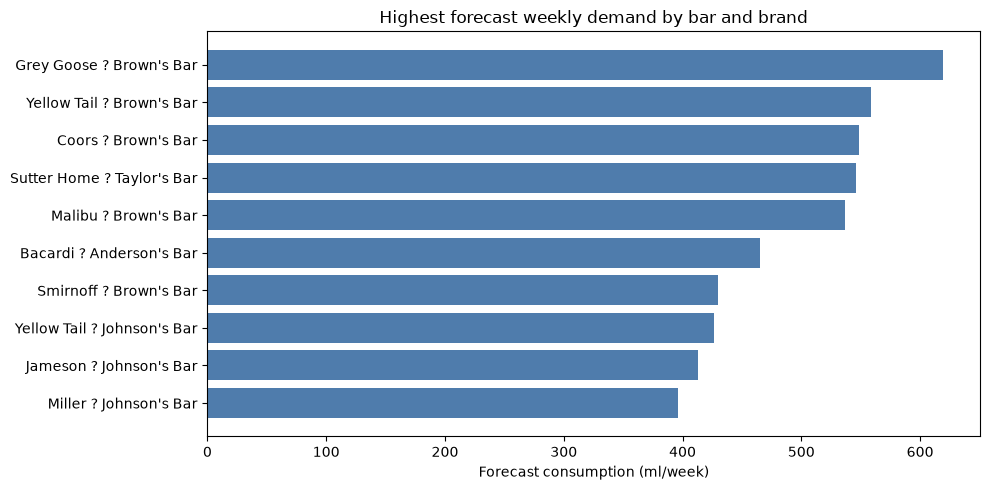

Saved 96 rows to C:\inventory_management_sys\inventory_recommendations.csv


In [7]:
top = recommendations.head(10).sort_values("forecast_weekly_ml")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top["Brand Name"] + " at " + top["Bar Name"],
        top["forecast_weekly_ml"], color="#4f7cac")
ax.set(title="Highest forecast weekly demand by bar and brand",
       xlabel="Forecast consumption (ml/week)")
plt.tight_layout()
plt.show()

OUTPUT_PATH = Path("inventory_recommendations.csv")
export = recommendations.assign(
    lead_time_days=LEAD_TIME_DAYS,
    review_period_days=REVIEW_PERIOD_DAYS,
    service_level=SERVICE_LEVEL,
    forecast_method=f"{FORECAST_WINDOW_WEEKS}-week moving average",
    source_data_through=as_of.date().isoformat(),
)
export.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {len(export)} rows to {OUTPUT_PATH.resolve()}")


## Assumptions to revisit

- No-row dates are treated as zero demand. Confirm whether the input is a complete movement log; improve collection before treating par quantities as dependable.
- Lead time is three days, review period is seven days, and service level is 95%. Replace these with supplier- and item-specific choices.
- The source ends on 1 January 2024. Its latest closing balances are historical and cannot represent current stock.
- Each combination has about 68 recorded days on average. The moving average is explainable and suitable as a baseline, but a longer complete history is needed to learn weekday, event, or annual seasonality.
- All outputs are in ml. The manager should apply package size, minimum order, shelf-life, and local constraints.
